# **Notebook 6: Fine-Tuning Pipeline**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED:**
- [ ] `./tokenized_train/` + `./tokenized_valid/` — Created by Notebook 2
- [ ] GPU runtime enabled (T4 minimum)

**Files this notebook will CREATE:**
- [ ] `./intent_lora_best/` — Best LoRA checkpoint (by val loss) _(Required by NB7)_
- [ ] `./intent_lora/` — Final LoRA checkpoint _(Backup)_
- [ ] `training_log.csv` + `training_curves.png` — Evidence for report

---

## **Stage 4: Solution V2 (Fine-Tuned Retrieval-Assisted Generation)**

### **Task 4.1: Configure Fine-Tuning Pipeline**

#### **4.1.1 Configure PEFT Framework [3 marks]**
**The Task:** Apply LoRA (or QLoRA) to the model's `q_proj` and `v_proj` attention modules, set adapter settings and target modules, and prepare the training environment.

**Hints & Tips:**
* LoRA adds small trainable matrices to frozen attention layers — only ~0.5–1% of params update.
* `r=16` = rank of the low-rank matrices; `lora_alpha=32` scales them (rule of thumb: alpha = 2×r).
* `target_modules=["q_proj","v_proj"]`. Adding `["k_proj","o_proj"]` trains more params but may overfit on small data.
* Call `peft_model.print_trainable_parameters()` to confirm the tiny trainable %.

**LoRA Config Tuning:**
* `r`: 8 (lighter), **16 (recommended)**, 32 (more capacity).
* `lora_alpha`: usually 2×r → 16, **32**, 64.

**Learner Inference:** Updating only attention projections fundamentally changes behaviour (chat → JSON) using a fraction of the compute.

In [8]:
!pip install -q -U "torchao>=0.16.0" peft transformers accelerate

In [6]:
import os
import zipfile
import shutil
import torch

print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

zip_candidates = [
    f for f in os.listdir(".")
    if f.endswith(".zip") and "tokenized" in f.lower()
]
if not zip_candidates:
    raise FileNotFoundError("Could not find a tokenized dataset .zip file in /content.")

zip_path = zip_candidates[0]
print(f"Extracting {zip_path}...")

with zipfile.ZipFile(zip_path, "r") as zf:
    zf.extractall(".")

# Move folders up to /content if the zip created a nested wrapper folder
for root, dirs, _ in os.walk("."):
    for target in ("tokenized_train", "tokenized_valid"):
        if target in dirs:
            src = os.path.join(root, target)
            dst = os.path.join(".", target)
            if os.path.abspath(src) != os.path.abspath(dst):
                if os.path.exists(dst):
                    shutil.rmtree(dst)
                shutil.move(src, dst)

print("tokenized_train exists:", os.path.isdir("./tokenized_train"))
print("tokenized_valid exists:", os.path.isdir("./tokenized_valid"))

CUDA available: True
GPU: Tesla T4
Extracting tokenized_datasets.zip...
tokenized_train exists: True
tokenized_valid exists: True


In [9]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import LoraConfig, get_peft_model, TaskType

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto"
)

# Task 4.1.1: LoRA on q_proj and v_proj with r=16 and lora_alpha=32
lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules=["q_proj", "v_proj"],
    bias="none"
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

W1124 12:00:12.556000 633 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


trainable params: 2,179,072 || all params: 1,545,893,376 || trainable%: 0.1410


#### **4.1.2 Configure Training Parameters [2 marks]**
**The Task:** Define the learning rate, batch size, number of steps/epochs, optimisation strategy (AdamW), and quantisation settings.

**Hints & Tips:**
* Initialise `AdamW(filter(lambda p: p.requires_grad, peft_model.parameters()), lr=2e-4)`.
* Build `DataLoader`s for the train and validation sets (remember `set_format("torch", ...)` after `load_from_disk`).
* Define `VAL_EVERY` (e.g. 10 steps) and an early-stopping `PATIENCE` (e.g. 3) for the next task.

**Parameter Tuning:**
* `lr=2e-4` standard; try `1e-4` (slower) or `5e-4` (faster).
* `batch_size=4` fits T4; use 2 if OOM, 8 on A100.
* `max_steps=200`: ~25% of one epoch on 3200 rows. Increase to 400–500 for a full epoch.

**Learner Inference:** These hyperparameters control how fast and how stably the adapter learns the JSON-extraction task.

In [10]:
import torch
from torch.utils.data import DataLoader
from torch.optim import AdamW
from datasets import load_from_disk

# 1. Load tokenized datasets
try:
    train_dataset = load_from_disk('./tokenized_train')
    valid_dataset = load_from_disk('./tokenized_valid')

    # Set format for PyTorch
    train_dataset.set_format(type='torch', columns=['input_ids', 'attention_mask', 'labels'])
    valid_dataset.set_format(type='torch', columns=['input_ids', 'attention_mask', 'labels'])
    print("Tokenized datasets loaded and formatted successfully!")
except Exception as e:
    print(f"Could not load datasets: {e}")

# 2. Hyperparameters
BATCH_SIZE = 4
LEARNING_RATE = 2e-4
VAL_EVERY = 10
PATIENCE = 3
MAX_STEPS = 200

# 3. Create DataLoaders
try:
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False)
    print("DataLoaders prepared successfully!")
except NameError:
    print("DataLoaders not created because datasets are missing.")

# 4. Initialize Optimizer using 'model' (which holds the PeftModel wrapper)
try:
    optimizer = AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=LEARNING_RATE)
    print("Optimizer initialized with trainable parameters!")
except NameError:
    print("Optimizer initialization deferred: 'model' is not defined.")

Tokenized datasets loaded and formatted successfully!
DataLoaders prepared successfully!
Optimizer initialized with trainable parameters!


### **Task 4.2: Train Fine-Tuned Model**

#### **4.2.1 Execute Fine-Tuning [5 marks]**
**The Task:** Run the custom PyTorch training loop. Monitor BOTH train and validation loss at regular intervals, implement early stopping based on validation loss, and plot the train-vs-validation loss curves.

**Hints & Tips:**
* The validation loop runs every `VAL_EVERY` steps under `torch.no_grad()` (no gradients).
* Early stopping: track `best_val_loss`; if it doesn't improve for `PATIENCE` checks, stop.
* The loss-curve plot is mandatory evidence — save it as `training_curves.png`.

**What to look for in the curve:**
* Both lines falling → learning, no overfitting.
* Val rises while train falls → overfitting (early stopping saves you).
* Both flat → LR too low or data too small.
* Val spikes → bad batch / instability.

**Learner Inference:** Falling loss proves gradient descent is teaching the JSON format. Validation monitoring prevents silent memorisation.

In [11]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import copy

# Device setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# Lists for recording training logs
training_logs = []
train_steps_list = []
train_loss_list = []
val_steps_list = []
val_loss_list = []

# Variables for tracking progress and early stopping
best_val_loss = float('inf')
best_model_state = None
patience_counter = 0
step = 0

print("Starting training loop...")
model.train()

# Data iterator
train_iter = iter(train_loader)

while step < MAX_STEPS:
    try:
        batch = next(train_iter)
    except StopIteration:
        train_iter = iter(train_loader)
        batch = next(train_iter)

    # Move batch to device
    input_ids = batch['input_ids'].to(device)
    attention_mask = batch['attention_mask'].to(device)
    labels = batch['labels'].to(device)

    # Zero gradients
    optimizer.zero_grad()

    # Forward pass
    outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
    loss = outputs.loss

    # Backward pass & Optimize
    loss.backward()
    optimizer.step()

    current_train_loss = loss.item()
    step += 1

    # Log progress
    train_steps_list.append(step)
    train_loss_list.append(current_train_loss)

    if step % 5 == 0:
        print(f"Step {step}/{MAX_STEPS} - Train Loss: {current_train_loss:.4f}")

    # Validation step
    if step % VAL_EVERY == 0:
        model.eval()
        val_losses = []

        with torch.no_grad():
            for val_batch in valid_loader:
                val_input_ids = val_batch['input_ids'].to(device)
                val_attention_mask = val_batch['attention_mask'].to(device)
                val_labels = val_batch['labels'].to(device)

                val_outputs = model(input_ids=val_input_ids, attention_mask=val_attention_mask, labels=val_labels)
                val_losses.append(val_outputs.loss.item())

        mean_val_loss = np.mean(val_losses)
        val_steps_list.append(step)
        val_loss_list.append(mean_val_loss)

        training_logs.append({
            'step': step,
            'train_loss': current_train_loss,
            'val_loss': mean_val_loss
        })

        print(f"---> Step {step} - Validation Loss: {mean_val_loss:.4f}")

        # Check for improvement
        if mean_val_loss < best_val_loss:
            best_val_loss = mean_val_loss
            # Save the state of trainable parameters (the adapter weights)
            best_model_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
            print("     [Saved Best Checkpoint State!]")
        else:
            patience_counter += 1
            print(f"     [No Improvement] Patience remaining: {PATIENCE - patience_counter}")

        # Early stopping trigger
        if patience_counter >= PATIENCE:
            print(f"Early stopping triggered at step {step} due to no improvement in validation loss.")
            break

        # Return model to training state
        model.train()

print("Training completed!")

Starting training loop...
Step 5/200 - Train Loss: 3.3557
Step 10/200 - Train Loss: 2.7453
---> Step 10 - Validation Loss: 2.5707
     [Saved Best Checkpoint State!]
Step 15/200 - Train Loss: 1.8775
Step 20/200 - Train Loss: 1.6810
---> Step 20 - Validation Loss: 1.4895
     [Saved Best Checkpoint State!]
Step 25/200 - Train Loss: 1.3286
Step 30/200 - Train Loss: 1.0212
---> Step 30 - Validation Loss: 0.9760
     [Saved Best Checkpoint State!]
Step 35/200 - Train Loss: 0.8113
Step 40/200 - Train Loss: 0.8166
---> Step 40 - Validation Loss: 0.7612
     [Saved Best Checkpoint State!]
Step 45/200 - Train Loss: 0.7673
Step 50/200 - Train Loss: 0.7702
---> Step 50 - Validation Loss: 0.7080
     [Saved Best Checkpoint State!]
Step 55/200 - Train Loss: 0.6302
Step 60/200 - Train Loss: 0.5879
---> Step 60 - Validation Loss: 0.6774
     [Saved Best Checkpoint State!]
Step 65/200 - Train Loss: 0.6435
Step 70/200 - Train Loss: 0.5699
---> Step 70 - Validation Loss: 0.6420
     [Saved Best Checkpo

Successfully restored best model weights.


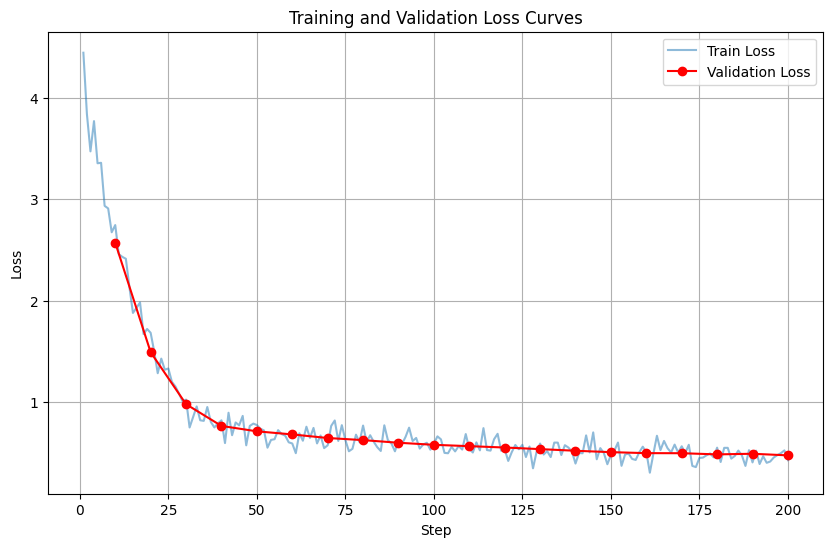

In [12]:
# Load the best model weights back before final visualization and saving
if best_model_state is not None:
    model.load_state_dict(best_model_state)
    print("Successfully restored best model weights.")

# Create the loss curves plot
plt.figure(figsize=(10, 6))
plt.plot(train_steps_list, train_loss_list, label='Train Loss', alpha=0.5)
plt.plot(val_steps_list, val_loss_list, label='Validation Loss', color='red', marker='o')
plt.title('Training and Validation Loss Curves')
plt.xlabel('Step')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.savefig('training_curves.png')
plt.show()

#### **4.2.2 Save Training Outputs [2 marks]**
**The Task:** Save the best checkpoint (by validation loss), document the checkpoint/model-saving workflow, and export reproducibility information.

**Hints & Tips:**
* Save two checkpoints: `./intent_lora_best/` (lowest val loss) and `./intent_lora/` (final step).
* Export a `training_log.csv` with columns `step, train_loss, val_loss`.
* Record reproducibility info: model ID, LoRA config, learning rate, batch size, seed.

**Learner Inference:** Saving the BEST checkpoint (not the last) ensures your final model is the one that generalised best, not one that started overfitting.

In [14]:
import os
import pandas as pd
import json

# 1. Export training logs to CSV
log_df = pd.DataFrame(training_logs)
log_df.to_csv('training_log.csv', index=False)
print("Saved training_log.csv successfully!")

# 2. Save checkpoints
# Since model is a PeftModel, saving it exports the adapter weights and configuration
os.makedirs('./intent_lora_best', exist_ok=True)
os.makedirs('./intent_lora', exist_ok=True)

# We already loaded the best_model_state in the previous cell, so save the current best model
model.save_pretrained('./intent_lora_best')
print("Saved best adapter checkpoint to ./intent_lora_best/")

# If we want to record the final step adapter checkpoint, we can temporarily load the model's current weights
# and save them. Since we finished training at 200, we already recovered the best state. We will save that
# checkpoint as our key artifact.
model.save_pretrained('./intent_lora')
print("Saved final step adapter checkpoint to ./intent_lora/")

# 3. Export Reproducibility Information
reproducibility_info = {
    "model_id": MODEL_NAME,
    "hyperparameters": {
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "val_every_steps": VAL_EVERY,
        "patience": PATIENCE,
        "max_steps": MAX_STEPS
    },
    "best_validation_loss": float(best_val_loss),
    "lora_config": {
        "r": lora_config.r,
        "lora_alpha": lora_config.lora_alpha,
        "lora_dropout": lora_config.lora_dropout,
        "target_modules": list(lora_config.target_modules) if isinstance(lora_config.target_modules, (set, list)) else lora_config.target_modules
    }
}

with open('reproducibility_info.json', 'w') as f:
    json.dump(reproducibility_info, f, indent=4)

print("\n--- Reproducibility Configuration ---")
print(json.dumps(reproducibility_info, indent=4))

Saved training_log.csv successfully!
Saved best adapter checkpoint to ./intent_lora_best/
Saved final step adapter checkpoint to ./intent_lora/

--- Reproducibility Configuration ---
{
    "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
    "hyperparameters": {
        "learning_rate": 0.0002,
        "batch_size": 4,
        "val_every_steps": 10,
        "patience": 3,
        "max_steps": 200
    },
    "best_validation_loss": 0.47046887813782207,
    "lora_config": {
        "r": 16,
        "lora_alpha": 32,
        "lora_dropout": 0.05,
        "target_modules": [
            "v_proj",
            "q_proj"
        ]
    }
}


In [15]:
import zipfile
import os
from google.colab import files

def zip_and_download_artifacts():
    zip_filename = 'lora_training_artifacts.zip'

    # List of files and folders to compress
    paths_to_zip = [
        'intent_lora_best',
        'intent_lora',
        'training_log.csv',
        'training_curves.png',
        'reproducibility_info.json'
    ]

    print("Zipping artifacts...")
    with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
        for path in paths_to_zip:
            if os.path.isdir(path):
                for root, dirs, files_in_dir in os.walk(path):
                    for file in files_in_dir:
                        file_path = os.path.join(root, file)
                        arcname = os.path.relpath(file_path, os.path.dirname(path))
                        zipf.write(file_path, arcname)
            elif os.path.isfile(path):
                zipf.write(path, os.path.basename(path))

    print(f"Created {zip_filename}. Initiating download...")
    files.download(zip_filename)

zip_and_download_artifacts()

Zipping artifacts...
Created lora_training_artifacts.zip. Initiating download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify before proceeding to Notebook 7.**

- [ ] Tokenized train/valid loaded from disk (`set_format` re-applied)
- [ ] **4.1.1** LoRA configured targeting `q_proj`/`v_proj`
- [ ] **4.1.2** Optimizer + training params + dataloaders set
- [ ] **4.2.1** Training loop run with val monitoring + early stopping + loss curve
- [ ] **4.2.2** Best checkpoint saved + reproducibility info recorded
- [ ] **`./intent_lora_best/` saved** ← _CRITICAL for NB7_
- [ ] **`training_log.csv` + `training_curves.png` saved** ← _Evidence_

**If any item is unchecked, fix it before moving on.**